# Sujet 3 — Notebook 3 : évaluation (version fusionnée)

**Jeu de test fusionné** : 40 ordonnances et 54 paires à risque attendues.

| Origine | Ordonnances | Paires | Particularités |
|---|---|---|---|
| Imane (O01-O20) | 20 | 26 | noms français et commerciaux, polymédication de 8, fluindione absente du graphe |
| Aziz (P01-P20) | 20 | 28 | ISRS/IRSN, hyperkaliémie, polymédication de 9, héparine absente du graphe |

Vérité terrain : niveaux de l'échelle du Thésaurus ANSM ; sources ANSM, RCP et étiquettes FDA (`donnees/verite_terrain.csv`). 16 paires sur 54 sont marquées « à vérifier ».

**Référence non hybride** : recherche exacte de la paire dans une liste de 26 interactions (`donnees/liste_paires_reference.csv`).

Dimensions couvertes : **performance**, **cohérence** (niveau de gravité, ordre des médicaments), **explicabilité**, **robustesse**, **calibration** (bonus ProbLog, notebook 4), **coût**.

In [1]:
from pathlib import Path
import sys
import pandas as pd

# Les modules sont dans src/. Sur Colab : importez le zip du projet puis exécutez
# !unzip -q <zip>   (le dossier projet/ apparaît à côté du notebook)
ICI = Path.cwd()
for c in [ICI, ICI / "src", ICI.parent / "src", ICI / "projet" / "src"]:
    if (c / "graphe.py").exists():
        sys.path.insert(0, str(c)); break

pd.set_option("display.max_colwidth", 110)
pd.set_option("display.width", 200)

import matplotlib.pyplot as plt
from graphe import charger_graphe
from regles import Verificateur
from evaluation import (charger_verite, evaluer, systeme_hybride, systeme_liste_paires, ablation,
                        par_famille, analyser_erreurs, robustesse, generalisation, par_origine, coherence)

G = charger_graphe()
_, verite = charger_verite()
print(len(verite), "paires attendues ;", verite.niveau.value_counts().sort_index().to_dict())

54 paires attendues ; {1: 15, 2: 20, 3: 14, 4: 5}


## 1. Avant la fusion : évaluation croisée des deux versions

Chaque version a d'abord été évaluée sur son propre jeu **et** sur celui de l'autre (calcul fait une fois, avant la fusion ; la version d'Aziz n'est pas incluse dans ce dépôt).

| Version | Sur les ordonnances d'Imane | Sur les ordonnances d'Aziz |
|---|---|---|
| Imane | F1 0,83 | F1 0,76 |
| Aziz (`ordo_check`) | F1 0,38 | F1 0,94 |

Chaque version était meilleure sur son propre jeu : un jeu de test écrit par l'auteur des règles surestime la performance. La version d'Imane généralisait mieux (table ATC, noms français, règles du graphe) ; celle d'Aziz couvrait des interactions absentes chez Imane (ISRS/IRSN + AINS ou AVK, antiagrégant + AINS, digoxine + macrolides, potassium + épargneurs). La fusion garde le code d'Imane et ajoute ces règles (R19-R24) et les deux jeux de test.

## 2. Résultat principal, par origine du jeu de test

In [2]:
display(par_origine(G))

,jeu de test,système,paires attendues,VP,FP,FN,précision,rappel,F1,alertes / ordonnance,niveau exact (VP),niveau ±1 (VP),ms / ordonnance
0,ordonnances d'Imane (O01-O20),Hybride,26,21,2,5,0.913,0.808,0.857,1.15,0.952,0.952,0.97
1,ordonnances d'Imane (O01-O20),Référence : liste de paires,26,11,0,15,1.000,0.423,0.595,0.55,1.000,1.000,0.01
2,ordonnances d'Aziz (P01-P20),Hybride,28,27,0,1,1.000,0.964,0.982,1.35,1.000,1.000,0.89
3,ordonnances d'Aziz (P01-P20),Référence : liste de paires,28,10,0,18,1.000,0.357,0.526,0.50,1.000,1.000,0.07
4,jeu fusionné (40),Hybride,54,48,2,6,0.960,0.889,0.923,1.25,0.979,0.979,0.91
5,jeu fusionné (40),Référence : liste de paires,54,21,0,33,1.000,0.389,0.560,0.53,1.000,1.000,0.04


**Lecture.** Sur le jeu fusionné, l'hybride atteint F1 0,92 contre 0,56 pour la liste de paires.

**Attention au biais** : les règles R19-R24 ont été ajoutées après avoir vu les ordonnances d'Aziz. Le score sur P01-P20 (F1 0,98) est donc optimiste. Le chiffre le plus honnête pour juger la généralisation reste celui de l'évaluation croisée avant fusion, et le test de généralisation (section 6).

## 3. Ablation : retirer une brique à la fois

In [3]:
abl = ablation(G)
display(abl)

,VP,FP,FN,précision,rappel,F1,alertes / ordonnance,niveau exact (VP),niveau ±1 (VP),ms / ordonnance
configuration,,,,,,,,,,
Hybride complet (concis),48,2,6,0.960,0.889,0.923,1.25,0.979,0.979,0.94
Hybride sans filtre anti-fatigue,51,70,3,0.421,0.944,0.583,3.02,0.941,0.961,1.00
– sans filtre « marge étroite » sur G1,48,16,6,0.750,0.889,0.814,1.60,0.979,0.979,0.95
+ corroboration G2+G3 (option),49,17,5,0.742,0.907,0.817,1.65,0.959,0.959,0.97
– sans règles expertes (graphe seul),10,1,44,0.909,0.185,0.308,0.28,0.900,0.900,0.35
– sans règle pharmacocinétique G1,41,1,13,0.976,0.759,0.854,1.05,1.000,1.000,0.85
– sans règles génériques G1-G3,41,1,13,0.976,0.759,0.854,1.05,1.000,1.000,0.57
– sans règles reprises d'Aziz (R19-R24),37,2,17,0.949,0.685,0.796,0.97,0.973,0.973,0.79
– sans table ATC (classes du graphe seules),30,1,24,0.968,0.556,0.706,0.78,0.967,0.967,0.88


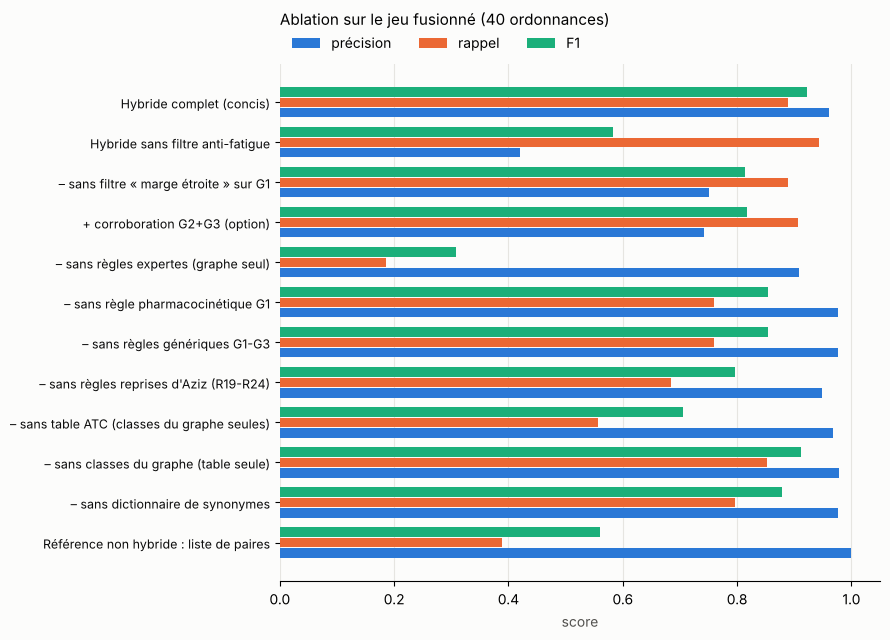

In [4]:
cfg = abl.index.tolist()[::-1]
y = range(len(cfg)); h = 0.26
couleurs = {"précision": "#2a78d6", "rappel": "#eb6834", "F1": "#1baf7a"}
fig, ax = plt.subplots(figsize=(9, 6.5), facecolor="#fcfcfb")
ax.set_facecolor("#fcfcfb")
for k, (m, c) in enumerate(couleurs.items()):
    ax.barh([i + (k - 1) * h for i in y], abl.loc[cfg, m], height=h * 0.9, color=c, label=m)
ax.set_yticks(list(y)); ax.set_yticklabels(cfg, fontsize=9, color="#0b0b0b")
ax.set_xlim(0, 1.05); ax.set_xlabel("score", color="#52514e")
ax.grid(axis="x", color="#e6e5e1", linewidth=0.8); ax.set_axisbelow(True)
for s in ("top", "right", "left"):
    ax.spines[s].set_visible(False)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=3, frameon=False)
ax.set_title("Ablation sur le jeu fusionné (40 ordonnances)", loc="left", fontsize=11, pad=28)
plt.tight_layout(); plt.show()

**Lecture de l'ablation (jeu fusionné).**

- **Règles expertes** : la brique principale ; sans elles (graphe seul), le rappel tombe de 0,89 à 0,19.
- **Règles reprises d'Aziz (R19-R24)** : sans elles, le rappel passe de 0,89 à 0,69. La fusion apporte 11 vraies alertes.
- **Règle pharmacocinétique G1** : elle ajoute 7 vraies alertes qu'aucune règle experte ne couvre (warfarine + fluconazole, + amiodarone, + clarithromycine, colchicine + clarithromycine, glibenclamide + fluconazole…), au prix d'une fausse alerte.
- **Filtre « marge étroite »** : sans lui, G1 produit 14 fausses alertes de plus. C'est l'association du mécanisme (graphe) et de la connaissance clinique qui rend la règle utile.
- **Filtre anti-fatigue** : sans lui, le rappel monte à 0,94 mais avec 70 fausses alertes (3 alertes par ordonnance).
- **Table ATC** : sans elle, le rappel tombe à 0,56 : le graphe ne classe ni les statines, ni les IEC, ni le potassium.
- **Classes du graphe** : les retirer change peu sur ce jeu, car la table a été écrite pour ses médicaments ; le test de généralisation (section 6) montre leur utilité.

## 4. Contribution de chaque famille de règles, seule

In [5]:
display(par_famille(G))

,famille seule,mode,VP,FP,FN,précision,rappel,F1,alertes / ordonnance,niveau exact (VP),niveau ±1 (VP),ms / ordonnance
0,classe,concis,41,1,13,0.976,0.759,0.854,1.05,1.00,1.000,0.58
1,classe,complet,41,1,13,0.976,0.759,0.854,1.05,1.00,1.000,0.58
2,pk,concis,10,1,44,0.909,0.185,0.308,0.28,0.90,0.900,0.08
3,pk,complet,12,15,42,0.444,0.222,0.296,0.68,0.75,0.750,0.08
4,effet,concis,0,0,54,0.000,0.000,0.000,0.00,NaN,NaN,0.28
5,effet,complet,35,67,19,0.343,0.648,0.449,2.55,0.40,0.571,0.31
6,cible,concis,0,0,54,0.000,0.000,0.000,0.00,NaN,NaN,0.06
7,cible,complet,2,3,52,0.400,0.037,0.068,0.12,0.50,0.500,0.07


## 5. Analyse d'erreurs : chaque erreur attribuée à sa brique

In [6]:
err = analyser_erreurs(G)
display(err)
display(err["brique responsable"].str.split(" :| \\(").str[0].value_counts().to_frame("erreurs"))

,ordonnance,paire,erreur,niveau attendu,niveau prédit,brique responsable
0,O01,Omeprazole + Warfarin,FP,NaN,2.0,Règle générique du graphe trop large (G1)
1,O02,Amlodipine + Simvastatin,FN,2.0,NaN,"Règle manquante : aucune règle experte, rien dans le graphe"
2,O05,Furosemide + Lisinopril,FN,2.0,NaN,"Filtre anti-fatigue : seulement G2 (niveau 1, masqué)"
3,O06,Ketoprofen + Prednisone,FN,1.0,NaN,"Filtre anti-fatigue : seulement G2 (niveau 1, masqué)"
4,O07,Digoxin + Furosemide,FN,2.0,NaN,"Règle manquante : aucune règle experte, rien dans le graphe"
5,O14,Allopurinol + Azathioprine,FN,3.0,NaN,"Filtre anti-fatigue : seulement G2, G3 (niveau 1, masqué)"
6,O18,Acetylsalicylic acid + Ramipril,FP,NaN,2.0,Classe du graphe trop large (R16)
7,P16,Digoxin + Furosemide,FN,2.0,NaN,"Règle manquante : aucune règle experte, rien dans le graphe"


,erreurs
brique responsable,
Règle manquante,3
Filtre anti-fatigue,3
Règle générique du graphe trop large,1
Classe du graphe trop large,1


**Lecture.**

| Brique | Erreurs | Explication |
|---|---|---|
| Filtre anti-fatigue | 3 oublis | seuls un effet partagé (G2) ou une cible commune (G3) signalaient la paire ; ces signaux de niveau 1 sont masqués. Allopurinol + azathioprine est un vrai cas où le graphe *savait* (cible commune XDH). |
| Règle manquante | 3 oublis | digoxine + furosémide (deux fois) et simvastatine + amlodipine : aucune règle, rien d'exploitable dans le graphe. |
| Graphe (classe trop large) | 1 fausse alerte | aspirine classée AINS dans Hetionet ; à dose antiagrégante, l'interaction AINS + IEC ne s'applique pas. |
| Graphe (règle G1) | 1 fausse alerte | oméprazole + warfarine : le graphe ne code pas la force de l'inhibition enzymatique. |

## 6. Cas difficiles : généralisation à des médicaments absents de la table

In [7]:
display(generalisation(G))

,VP,FP,FN,précision,rappel,F1,alertes / ordonnance,niveau exact (VP),niveau ±1 (VP),ms / ordonnance
configuration,,,,,,,,,,
Hybride (graphe + table),5,0,0,1.0,1.0,1.000,1.0,1.0,1.0,0.51
Table ATC seule,0,0,5,0.0,0.0,0.000,0.0,NaN,NaN,0.32
Classes du graphe seules,2,0,3,1.0,0.4,0.571,0.4,1.0,1.0,0.42
Référence : liste de paires,0,0,5,0.0,0.0,0.000,0.0,NaN,NaN,0.01


**Lecture.** Sur 5 ordonnances dont l'AINS ou l'antiagrégant n'est **pas** dans la table (célécoxib, méloxicam, indométacine, piroxicam, ticlopidine), la table seule et la liste de paires ne trouvent rien ; le graphe classe ces médicaments et la règle experte s'applique. Les classes du graphe seules n'en trouvent que 2 sur 5. **Les deux sources de connaissance sont complémentaires.**

## 7. Robustesse : variantes de saisie des noms

In [8]:
display(robustesse(G))

,variante de saisie,reconnaissance,non reconnus,reconnus « à confirmer »,rappel,précision
0,saisie d'origine,synonymes + approché,1,0,0.889,0.96
1,saisie d'origine,synonymes seuls,1,0,0.889,0.96
2,saisie d'origine,aucun (noms du graphe),32,0,0.611,1.00
3,MAJUSCULES,synonymes + approché,1,0,0.889,0.96
4,MAJUSCULES,synonymes seuls,1,0,0.889,0.96
5,MAJUSCULES,aucun (noms du graphe),32,0,0.611,1.00
6,sans accents,synonymes + approché,1,0,0.889,0.96
7,sans accents,synonymes seuls,1,0,0.889,0.96
8,sans accents,aucun (noms du graphe),29,0,0.611,1.00
9,faute de frappe (lettre doublée),synonymes + approché,1,117,0.889,0.96


**Lecture.** Le seul médicament non reconnu est l'héparine (P20), absente du graphe et volontairement absente de la table : elle est signalée, jamais ignorée. Sans dictionnaire de synonymes, 32 noms ne sont pas reconnus et le rappel tombe à 0,61. Avec une faute de frappe dans chaque nom, la correspondance approchée garde le rappel à 0,89 et signale chaque nom deviné « à confirmer ».

## 8. Cohérence : l'ordre des médicaments ne change pas le résultat

Test repris de la version d'Aziz : chaque ordonnance est mélangée 5 fois ; les alertes, leurs niveaux et leurs règles doivent être identiques.

In [9]:
display(pd.Series(coherence(G)).to_frame("valeur"))

,valeur
ordonnances,40
permutations testées,200
résultats incohérents,0


## 9. Coût et explicabilité

- **Alertes par ordonnance** : 1,25 en mode concis contre 3,02 en mode complet.
- **Temps** : environ 1 ms par ordonnance une fois le graphe chargé (chargement initial : environ 2 s).
- **Explicabilité** : 100 % des alertes portent la règle, sa source et le chemin dans le graphe ou la ligne de table.

In [10]:
from reference_llm import ollama_disponible, systeme_llm
if ollama_disponible():
    res_llm, _ = evaluer(systeme_llm(Verificateur(G), modele="llama3.2:3b"))
    display(pd.DataFrame({"LLM sans graphe": res_llm}).T)
else:
    print("Ollama n'est pas lancé : deuxième référence (LLM sans graphe) non évaluée.")
    print("Pour l'activer : installer Ollama, `ollama pull llama3.2:3b`, puis relancer cette cellule.")

Ollama n'est pas lancé : deuxième référence (LLM sans graphe) non évaluée.
Pour l'activer : installer Ollama, `ollama pull llama3.2:3b`, puis relancer cette cellule.
